# Power against underestimated PDs, and the exact rejection probabilities that need no simulation

**Question:** How much must a PD be underestimated before the calibration tests catch it with 80% power, and which tests need the largest error to do so?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic (the rate and its Monte Carlo error, the size of every test)
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- plant an underestimated PD of known size with the study's generator and see what one dataset looks like to a calibration test;
- compute the exact power of a count test with `rejection_probability`, with no simulation, and say why the engine can do it;
- check simulated power against that exact curve, point by point, on the whole ladder of the study;
- find, with a root finder, the severity at which a test reaches 80% power and compare the tests with it;
- explain why the default-profile test is blind to a PD that is too low by the same factor in every grade, and what the Vasicek correction costs in power.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import optimize

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is the `miscalibration` family of case C22, validating the validator. In every dataset the PDs given to the test are $1/k$ of the true PDs, so the model underestimates risk by the factor $k$, which runs on a ladder from 1 (no defect) to 3. The datasets are drawn by known-truth generators of `riskvalidation.generators` (licence MIT, class `generated`); the truth of each says how many defaults to expect and whether the null holds.

- **File read:** `data/derived/C22/miscalibration.json`, keys `outputs` (the simulations, the generators and the ladder), `impact` and `provenance`.
- **What is taken from it:** the generator configuration, seed and repetitions of each rung. The engine draws the datasets again here and measures the power.

The next cell loads the file, indexes the rows and prints the ladder with the engine versions.

In [2]:
# Load the miscalibration family and index its simulations by key
LANG = "en"
ROOT = Path("../../..").resolve()
miscal = json.loads((ROOT / "data" / "derived" / "C22" / "miscalibration.json").read_text(encoding="utf-8"))
out = miscal["outputs"]
rows = {row["key"]: row for row in out["simulations"]}
ladder = out["ladder"]["values"]
print("ladder of the factor k:", ladder, "|", "simulations:", len(rows))
print("baked by riskvalidation", miscal["provenance"]["riskvalidation_version"], "|", "installed", rv.__version__)

ladder of the factor k: [1.0, 1.1, 1.25, 1.5, 2.0, 3.0] | simulations: 54
baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

The power of a test against a defect is its rejection probability when the defect is present, here at the 5% level. For a test that sees the portfolio only through its default count $D$, the rejection region is $D \ge k^*$ and the power is a binomial tail,

$$\text{power}(k) = P\bigl(D \ge k^*\bigr), \qquad D \sim \mathrm{Binomial}(n,\ k\,\pi_{\text{applied}}),$$

so the engine can compute it exactly by finding $k^*$ with the registered test. For the tests that look at grades, obligors or years there is no closed form, and the power is a rejection rate over repetitions with its Wilson interval (notebook 01). The steps plant the defect on one dataset, compute the exact power of the count tests, check simulation against it, locate the severity of 80% power, and then measure the tests that have no exact value.

### Step 1: the planted defect on one dataset

The rung $k = 1.5$ is a portfolio of 5,000 obligors with a true PD of 3% where the model applies 2%. The generator's `truth()` states what is planted, and the next cell draws one dataset with a fixed seed, feeds it to the binomial and Jeffreys tests through `feed_cell` and prints their p-values and traffic lights.

In [3]:
# Draw one dataset with the planted defect k = 1.5 and run the binomial and Jeffreys tests on it
from riskvalidation.generators.counts import DefaultCounts, feed_cell
from riskvalidation.validation.calibration import pd_binomial, pd_jeffreys

spec = out["generators"]["port-5000-k1.5"]
generator = DefaultCounts(**spec["config"])
truth = generator.truth()
print("true PD:", truth["pd_true"][0][0], "| PD applied:", truth["pd_forecast"][0][0])
print("expected defaults, true:", truth["expected_defaults"][0][0])
print("the null holds:", truth["calibration_null_holds"])
cell = feed_cell()(generator.draw(np.random.default_rng(5)))
print("obligors:", cell["n"], "| defaults observed:", cell["d"])
for test in (pd_binomial, pd_jeffreys):
    result = test(**cell)
    print(f"{result.test_id:12s} p = {result.p_value:.2e} | light {result.light.value}")

true PD: 0.03 | PD applied: 0.02
expected defaults, true: 150.0
the null holds: False
obligors: 5000 | defaults observed: 159
pd.binomial  p = 2.31e-08 | light red
pd.jeffreys  p = 1.81e-08 | light red


The portfolio should have 150 defaults where the PD applied expects 100, and the dataset drawn has 159. Both tests are red, with p-values of 2.31e-08 for the binomial and 1.81e-08 for the Jeffreys test: at this severity and size the defect is plain to see. The question of the ladder is how small a defect can be before one dataset stops showing it, and for that a single draw is useless, since one p-value says nothing about how often the test would catch a given factor.

### Step 2: exact power, with no simulation

`critical_count` calls the registered test on every count until one rejects, and `rejection_probability` returns the binomial tail beyond it. The next cell computes the exact power of the binomial, Jeffreys and Vasicek-corrected tests for factors from 1 to 3 on a fine grid, prints the critical count of each and the power at $k = 1.5$, and draws the three curves with the 80% line. The corrected test assumes an asset correlation of 12%, so its critical count is much higher.

pd.binomial          critical count 118 | power at k = 1.5 0.9973
pd.jeffreys          critical count 117 | power at k = 1.5 0.9980
pd.binomial_vasicek  critical count 287 | power at k = 1.5 0.0000


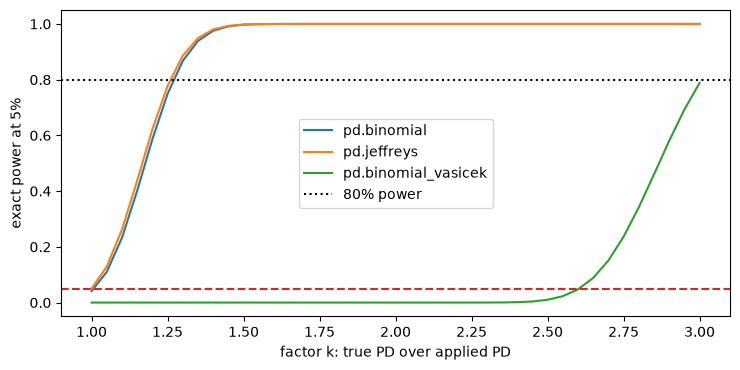

In [4]:
# Exact power of the three count tests for a finer grid of the factor k, and the critical count of each
from riskvalidation.harness.exact import critical_count, rejection_probability

extra = {"pd.binomial": {}, "pd.jeffreys": {}, "pd.binomial_vasicek": {"rho": 0.12}}
ks = np.linspace(1.0, 3.0, 41)
power = {}
for test, kw in extra.items():
    power[test] = [rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k, **kw)["probability"] for k in ks]
    k_star = critical_count(test, 5000, 0.02, 0.05, **kw)
    print(f"{test:20s} critical count {k_star} | power at k = 1.5 {power[test][10]:.4f}")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for test in extra:
    ax.plot(ks, power[test], label=test)
ax.axhline(0.8, color="black", linestyle=":", label="80% power")
ax.axhline(0.05, color="tab:red", linestyle="--")
ax.set_xlabel("factor k: true PD over applied PD")
ax.set_ylabel("exact power at 5%")
ax.legend()
fig.tight_layout()
plt.show()

The binomial and Jeffreys curves climb together and reach full power before $k = 1.5$: at that rung their powers are 0.9973 and 0.9980, with critical counts of 118 and 117 defaults against the 100 expected. The corrected test is a different story. It needs 287 defaults to reject, so at $k = 1.5$ its power is 0.0000 and its curve only rises at the right end of the ladder. The correction protects against false alarms under correlation, and the figure shows what it takes from the power under independence.

### Step 3: does simulation agree with the exact curve?

Each rung of the ladder has a committed seed and a generator configuration. The next cell runs the three tests on all six rungs with `simulate`, 2,000 repetitions each, computes the exact power at the same rung, prints the largest standardised gap among the 18 points, and draws the simulated rates with their Wilson intervals on the exact curves of the previous step.

points simulated: 18 | largest standardised gap: 2.14


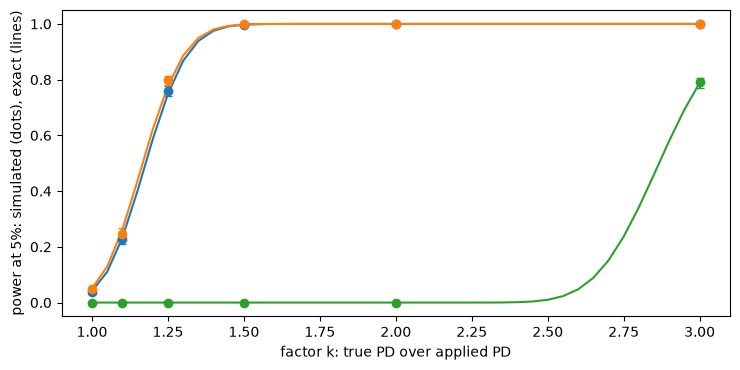

In [5]:
# Simulate the three tests on every rung of the ladder and set each rate against the exact curve
from riskvalidation.harness.run import simulate

fig, ax = plt.subplots(figsize=(7.5, 3.8))
largest = 0.0
for index, (test, kw) in enumerate(extra.items()):
    ax.plot(ks, power[test], color=f"C{index}")
    for k in ladder:
        row = rows[f"{test}@k{k:g}"]
        gen = DefaultCounts(**out["generators"][row["generator"]]["config"])
        run = simulate(test, gen, n_rep=row["n_rep"], seed=row["seed"], feed=feed_cell(), test_kwargs=kw)
        measured = run.rates["p<0.05"]
        exact = rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k, **kw)["probability"]
        low, high = measured.interval
        errors = [[measured.rate - low], [high - measured.rate]]
        ax.errorbar(k, measured.rate, yerr=errors, fmt="o", capsize=3, color=f"C{index}")
        if 0 < exact < 1:
            largest = max(largest, abs(measured.rate - exact) / np.sqrt(exact * (1 - exact) / measured.n))
print("points simulated:", 3 * len(ladder), "| largest standardised gap:", round(float(largest), 2))
ax.set_xlabel("factor k: true PD over applied PD")
ax.set_ylabel("power at 5%: simulated (dots), exact (lines)")
fig.tight_layout()
plt.show()

All 18 simulated points sit on their exact curves, and the largest standardised gap is 2.14, below the 3.29 criterion used in the study. The agreement matters beyond the count tests: it shows that the generator, the harness and the registered tests are wired correctly, so the rates of the tests that have no exact value, measured by the same machinery in step 5, can be trusted on the same footing. The intervals at the extremes are tiny because the power there is close to 0 or 1.

### Step 4: the severity of 80% power

Power is a nondecreasing function of $k$, so the factor at which a test reaches 80% is the root of $\text{power}(k) - 0.8$. The next cell finds it with a bracketing root finder (`scipy.optimize.brentq`) on the engine's exact power for the three count tests, and prints the true PD that factor corresponds to, beside the value the artifact reports for the Jeffreys test.

In [6]:
# Find the factor k at which each count test reaches 80% power
def power_gap(k, test, kw):
    return rejection_probability(test, 5000, 0.02, 0.05, pd_true=0.02 * k, **kw)["probability"] - 0.8


k80 = {}
for test, kw in extra.items():
    k80[test] = optimize.brentq(power_gap, 1.0, 4.0, args=(test, kw), xtol=1e-9)
    print(f"{test:20s} k at 80% power {k80[test]:.4f} | true PD {0.02 * k80[test]:.4f}")
print("headline of the file, Jeffreys:", round(miscal["impact"]["jeffreys_k80"]["value"], 4))

pd.binomial          k at 80% power 1.2690 | true PD 0.0254
pd.jeffreys          k at 80% power 1.2587 | true PD 0.0252
pd.binomial_vasicek  k at 80% power 3.0069 | true PD 0.0601
headline of the file, Jeffreys: 1.2587


The binomial test reaches 80% power at $k = 1.2690$ and the Jeffreys test at $1.2587$, so both catch a true PD of about 2.5% against 2% applied, an underestimation of a quarter, four times out of five. The value of the file for the Jeffreys test, 1.2587, is what the root finder returns. The corrected test needs $k = 3.0069$, a true PD of 6.01%: to protect itself against a correlation of 12% it gives up almost all its sensitivity to a PD that is too low by a quarter or even a half.

### Step 5: the tests with no exact value

Three panels hold the tests that look at the rating grades (chi-square over seven grades and the default-profile test), at the obligors (Hosmer-Lemeshow and Spiegelhalter on a logistic model) and at the years (the normal test and the traffic lights over five years). The next cell rebuilds the generator of each rung from the file, picks the right feed for its shape, simulates each test and draws the power along the ladder, one panel per family.

pd.chi2_grades           [0.053, 0.16, 0.661, 0.995, 1.0, 1.0]
pd.default_profile       [0.033, 0.038, 0.037, 0.036, 0.033, 0.024]
pd.hosmer_lemeshow       [0.05, 0.168, 0.649, 0.995, 1.0, 1.0]
pd.spiegelhalter         [0.053, 0.412, 0.946, 1.0, 1.0, 1.0]
pd.normal_multiperiod    [0.077, 0.37, 0.863, 1.0, 1.0, 1.0]
pd.traffic_lights        [0.043, 0.278, 0.806, 1.0, 1.0, 1.0]


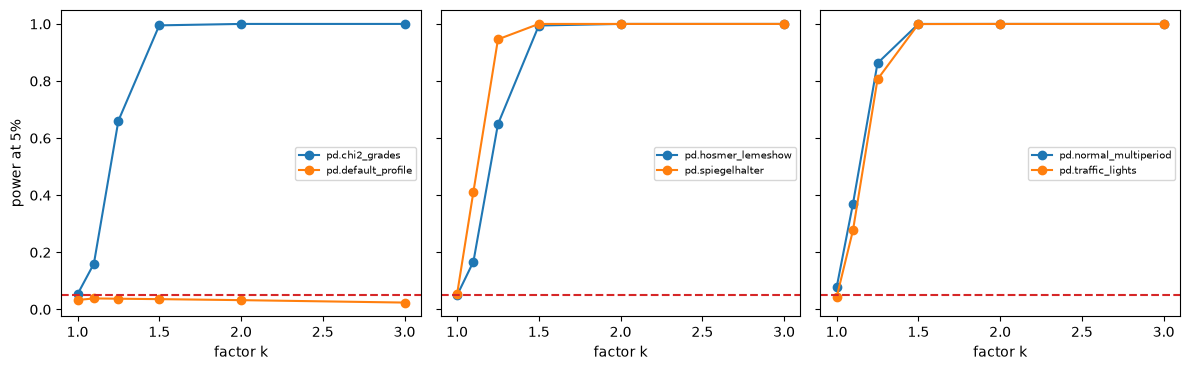

In [7]:
# Simulate the tests of the grades, obligors and years panels along the ladder and draw the four panels
from riskvalidation.generators.counts import feed_grades, feed_series
from riskvalidation.generators.scores import LogisticPortfolio

CLASSES = {cls.name: cls for cls in (DefaultCounts, LogisticPortfolio)}
KWARGS = {"pd.default_profile": {"n_sim": 2000}}
panels = {"grades": ("pd.chi2_grades", "pd.default_profile"), "obligors": ("pd.hosmer_lemeshow", "pd.spiegelhalter"),
          "years": ("pd.normal_multiperiod", "pd.traffic_lights")}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (panel, tests) in zip(axes, panels.items()):
    for index, test in enumerate(tests):
        rates = []
        for k in ladder:
            row = rows[f"{test}@k{k:g}"]
            cfg = out["generators"][row["generator"]]
            shape = cfg["config"].get("obligors", [[0]])
            feed = feed_series() if len(shape) > 1 else (feed_grades() if len(shape[0]) > 1 else feed_cell())
            gen = CLASSES[cfg["name"]](**cfg["config"])
            feed = None if cfg["name"] == "logistic_portfolio" else feed
            run = simulate(test, gen, n_rep=row["n_rep"], seed=row["seed"], feed=feed, test_kwargs=KWARGS.get(test))
            rates.append(run.rates["p<0.05"].rate)
        ax.plot(ladder, rates, "o-", label=test)
        print(f"{test:24s}", [round(r, 3) for r in rates])
    ax.axhline(0.05, color="tab:red", linestyle="--")
    ax.set_xlabel("factor k")
    ax.legend(fontsize=7)
axes[0].set_ylabel("power at 5%")
fig.tight_layout()
plt.show()

In the grades panel, the chi-square test climbs from 0.053 at $k = 1$ to 0.995 at $k = 1.5$, while the default-profile test stays between 0.024 and 0.038 along the whole ladder. It compares the shape of the defaults over the grades, and a PD too low by the same factor in every grade leaves the shape intact. Among the tests on obligors, Spiegelhalter is the most sensitive, with 0.946 at $k = 1.25$ against 0.649 for Hosmer-Lemeshow. Over five years the normal test reaches 0.863 at $k = 1.25$ and the traffic lights 0.806.

### Step 6: what the Vasicek correction costs

The correction exists for a reason (notebook 04 shows the false alarms of the uncorrected test under correlation). Its price is power when the defaults are in fact independent, as in this ladder. The next cell computes the exact power of both tests at factors beyond the committed ladder, from 2.5 to 4, and prints the 80% factors of the two.

In [8]:
# Exact power of the Vasicek-corrected test beyond the ladder and its factor k at 80% power
for k in (2.5, 3.0, 3.5, 4.0):
    plain = rejection_probability("pd.binomial", 5000, 0.02, 0.05, pd_true=0.02 * k)["probability"]
    pd_true = 0.02 * k
    corrected = rejection_probability("pd.binomial_vasicek", 5000, 0.02, 0.05, pd_true=pd_true, rho=0.12)["probability"]
    print(f"k = {k:3.1f} | binomial {plain:.4f} | corrected for correlation {corrected:.4f}")
print("k at 80% power, corrected:", round(k80["pd.binomial_vasicek"], 4))
print("k at 80% power, binomial:", round(k80["pd.binomial"], 4))

k = 2.5 | binomial 1.0000 | corrected for correlation 0.0100
k = 3.0 | binomial 1.0000 | corrected for correlation 0.7884
k = 3.5 | binomial 1.0000 | corrected for correlation 0.9999
k = 4.0 | binomial 1.0000 | corrected for correlation 1.0000
k at 80% power, corrected: 3.0069
k at 80% power, binomial: 1.269


Beyond the ladder the contrast is complete. The uncorrected binomial test has a power of 1.0000 from $k = 2.5$ on, while the corrected one rises from 0.0100 at $k = 2.5$ to 0.7884 at $k = 3.0$, 0.9999 at 3.5 and 1.0000 at 4.0. A validator who applies the correction chooses a test that is silent about an underestimation by a factor of 2.5, a defect that most banks would want to hear about. The right choice depends on whether defaults are correlated, which the next notebook measures.

## Results

**Answer:** For 5,000 obligors and a PD of 2% applied, the binomial and Jeffreys tests catch a true PD of about 2.5% four times out of five: they reach 80% power at $k = 1.2690$ and $k = 1.2587$. The corrected binomial test needs $k = 3.0069$, a true PD of 6.01%, and the default-profile test never exceeds 0.038 along the ladder, so it reaches 80% power at no factor tested. Among the tests with no exact value, Spiegelhalter reaches 0.946 power at $k = 1.25$ against 0.649 for Hosmer-Lemeshow.

- **One dataset is not a power.** At $k = 1.5$ a single draw of 159 defaults gives p-values of 2.31e-08, but the power of the same tests is 0.9973 and 0.9980, a statement about repetitions.
- **Exact and simulated power agree.** The largest standardised gap among 18 points is 2.14.
- **A correction has a price.** At $k = 1.5$ the corrected test has power 0.0000 and at $k = 2.5$ only 0.0100, against 1.0000 for the uncorrected one.
- **A test can be blind to a defect.** The default-profile test reads the shape of the defaults over the grades and a uniform factor does not change it.

Power under correlated defaults, where the corrected test earns its keep, is the work of notebook 04.

## Summary

- Power is a rejection probability against a planted defect: here every true PD is $k$ times the PD applied, for $k$ from 1 to 3.
- For the count tests the power is a binomial tail that the engine computes by calling the test, and 18 simulated points agree with it.
- The binomial and Jeffreys tests reach 80% power at about a quarter of underestimation; the corrected test needs a factor of 3.
- The default-profile test is blind to a uniform factor, and the chi-square, Hosmer-Lemeshow and Spiegelhalter tests are not.
- A correction against correlation is bought with power when defaults are independent.

**What to try next.** Change the number of obligors in the generator configuration to 1,000 and see where the 80% factor moves, then read notebook 04.

## References

- Morris, T. P., White, I. R. and Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): the one-factor default model, the binomial test and its Vasicek-type correction, the chi-square test over grades and the traffic-lights test. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, section 2.5.3.1 (the Jeffreys test). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Hosmer, D. W. and Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Spiegelhalter, D. J. (1986), Probabilistic prediction in patient management and clinical trials, Statistics in Medicine 5(5). https://doi.org/10.1002/sim.4780050506
- This repository: `docs/design/features/c22-validator/requirements.md` and `data-pipeline/pipeline/cases/c22_validator.py`, which wrote the artifact.